# Evolução dos votos por candidato

Este notebook reconstrói a evolução da apuração do 2º turno de 2022 usando
`DT_BU_RECEBIDO`, que representa o recebimento do boletim de urna. Cada candidato
aparece em uma linha própria.

**Critérios:** somente votos nominais (`CD_TIPO_VOTAVEL = 1`); eventos com o mesmo
minuto formam um lote visual; os votos são acumulados em ordem crescente de
recebimento. O agrupamento por minuto melhora a leitura, mas não inventa uma ordem
entre boletins recebidos no mesmo segundo.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

%matplotlib inline

def localizar_raiz(inicio: Path) -> Path:
    inicio = inicio.resolve()
    for pasta in (inicio, *inicio.parents):
        if (pasta / "04_bi" / "dados" / "fato_votos").exists():
            return pasta
    raise FileNotFoundError("Não foi possível localizar 04_bi/dados/fato_votos")

RAIZ = localizar_raiz(Path.cwd())
FATOS = RAIZ / "04_bi" / "dados" / "fato_votos" / "**" / "*.parquet"
DIM_VOTAVEL = RAIZ / "04_bi" / "dados" / "dimensoes" / "dim_votavel.parquet"

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (14, 7), "font.size": 11})
pd.set_option("display.max_rows", 20)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")

print(f"Raiz localizada: {RAIZ}")

Raiz localizada: /home/administrador/Downloads/Apuracoes/2t2022


## Parâmetros

O padrão mostra Presidente no Brasil inteiro. Para analisar uma UF, altere `UF`
para uma sigla como `"SP"`. Para Governador, use `CARGO = 3` e selecione uma UF.

In [2]:
CARGO = 1       # 1 = Presidente; 3 = Governador
UF = None       # None = Brasil inteiro; exemplo: "SP"
JANELA = "1min" # resolução visual do gráfico

if CARGO == 3 and UF is None:
    print("Aviso: para Governador, selecione uma UF para evitar misturar disputas estaduais.")

## Extração e preparação da série temporal

In [3]:
con = duckdb.connect()
caminho_fatos = str(FATOS).replace("'", "''")
caminho_dim = str(DIM_VOTAVEL).replace("'", "''")

filtro_uf = "AND v.sg_uf = ?" if UF else ""
parametros = [CARGO] + ([UF.upper()] if UF else [])

consulta = f"""
    SELECT
        date_trunc('minute', v.dt_bu_recebido) AS instante,
        concat(d.nm_votavel, ' (', d.nr_votavel, ')') AS candidato,
        sum(v.qt_votos)::BIGINT AS votos_no_lote
    FROM read_parquet('{caminho_fatos}', hive_partitioning=true) v
    JOIN read_parquet('{caminho_dim}') d USING (id_votavel)
    WHERE v.cd_cargo = ?
      AND d.cd_tipo_votavel = 1
      {filtro_uf}
    GROUP BY instante, candidato
    ORDER BY instante, candidato
"""

lotes = con.execute(consulta, parametros).df()
if lotes.empty:
    raise ValueError("A seleção não retornou votos. Revise CARGO e UF.")

incrementos = (
    lotes.pivot_table(index="instante", columns="candidato", values="votos_no_lote", aggfunc="sum")
    .fillna(0)
    .sort_index()
)
indice_completo = pd.date_range(incrementos.index.min(), incrementos.index.max(), freq=JANELA)
incrementos = incrementos.reindex(indice_completo, fill_value=0)
incrementos.index.name = "instante"
acumulado = incrementos.cumsum()

print(f"Período: {acumulado.index.min()} a {acumulado.index.max()}")
print(f"Pontos por linha: {len(acumulado):,}")
print(f"Candidatos: {', '.join(acumulado.columns)}")

Período: 2022-10-30 01:20:00 a 2022-10-31 00:17:00
Pontos por linha: 1,378
Candidatos: JAIR BOLSONARO (22), LULA (13)


## Validação da série

A célula abaixo confere novamente o total diretamente no fato e garante que nenhuma
linha acumulada diminua. Se houver divergência, a execução para com erro.

In [4]:
consulta_total = f"""
    SELECT sum(v.qt_votos)::BIGINT
    FROM read_parquet('{caminho_fatos}', hive_partitioning=true) v
    JOIN read_parquet('{caminho_dim}') d USING (id_votavel)
    WHERE v.cd_cargo = ?
      AND d.cd_tipo_votavel = 1
      {filtro_uf}
"""
total_fato = con.execute(consulta_total, parametros).fetchone()[0]
total_serie = int(incrementos.to_numpy().sum())
monotono = bool(acumulado.diff().fillna(acumulado).ge(0).all().all())

assert total_serie == total_fato, f"Divergência: série={total_serie}, fato={total_fato}"
assert monotono, "Ao menos uma série acumulada diminuiu."

validacao = pd.DataFrame({
    "controle": ["Total da série = total do fato", "Séries acumuladas não diminuem"],
    "resultado": ["OK", "OK"],
    "valor": [f"{total_serie:,}", monotono],
})
display(validacao)

,controle,resultado,valor
0,Total da série = total do fato,OK,"118,552,353"
1,Séries acumuladas não diminuem,OK,True


## Resultado final da seleção

In [5]:
resultado = acumulado.iloc[-1].sort_values(ascending=False).rename("votos").to_frame()
resultado["percentual_validos"] = resultado["votos"] / resultado["votos"].sum() * 100
resultado["votos_formatados"] = resultado["votos"].map(lambda x: f"{int(x):,}".replace(",", "."))
display(resultado[["votos_formatados", "percentual_validos"]])

,votos_formatados,percentual_validos
candidato,,
LULA (13),60.345.999,50.90
JAIR BOLSONARO (22),58.206.354,49.10


## Votos acumulados

Cada linha representa um candidato. O eixo horizontal segue a data/hora de recebimento
dos boletins; o eixo vertical mostra votos nominais acumulados.

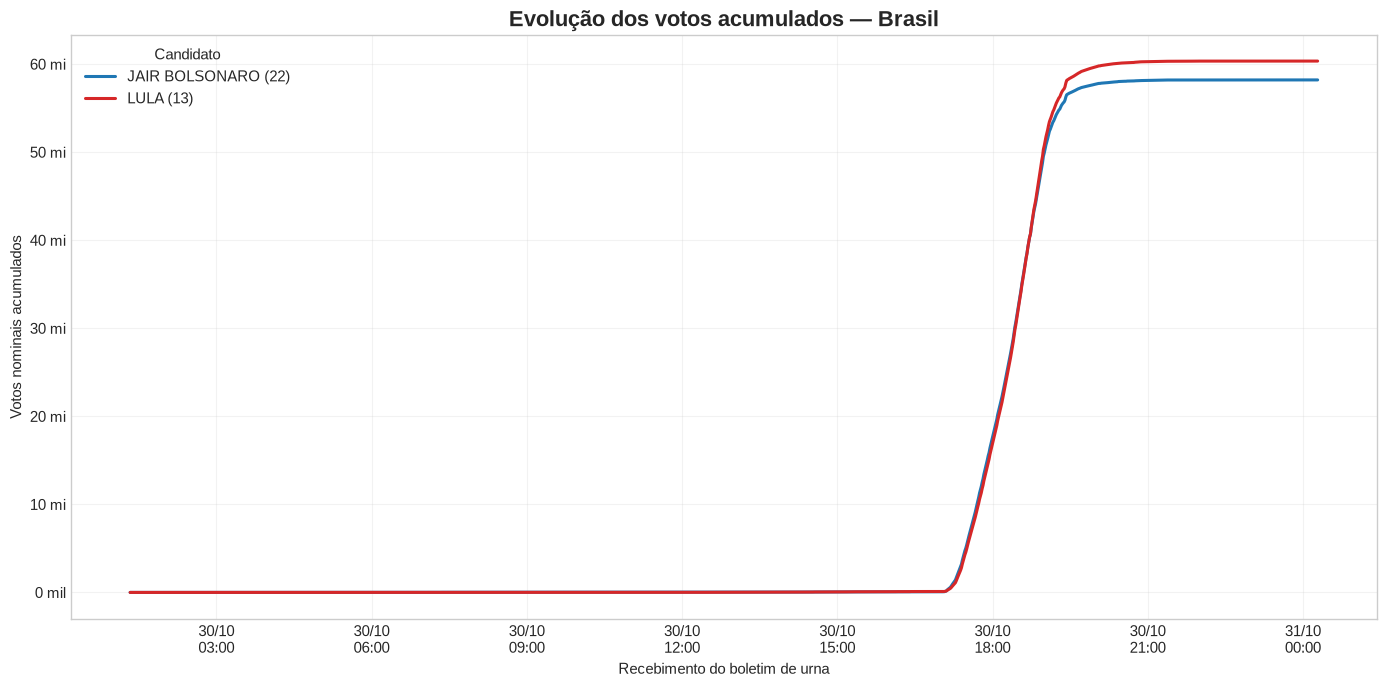

In [6]:
cores = {"LULA (13)": "#D62728", "JAIR BOLSONARO (22)": "#1F77B4"}
fig, ax = plt.subplots()
for candidato in acumulado.columns:
    ax.plot(
        acumulado.index,
        acumulado[candidato],
        label=candidato,
        linewidth=2.2,
        color=cores.get(candidato),
    )

local = "Brasil" if UF is None else UF.upper()
ax.set_title(f"Evolução dos votos acumulados — {local}", fontsize=16, weight="bold")
ax.set_xlabel("Recebimento do boletim de urna")
ax.set_ylabel("Votos nominais acumulados")
ax.ticklabel_format(style="plain", axis="y")
ax.yaxis.set_major_formatter(lambda x, pos: f"{x/1_000_000:.0f} mi" if x >= 1_000_000 else f"{x/1_000:.0f} mil")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))
ax.legend(title="Candidato", loc="upper left")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## Participação nos votos válidos ao longo da apuração

Este gráfico usa apenas os candidatos selecionados; branco e nulo não entram no
denominador. Oscilações no início refletem poucos boletins recebidos.

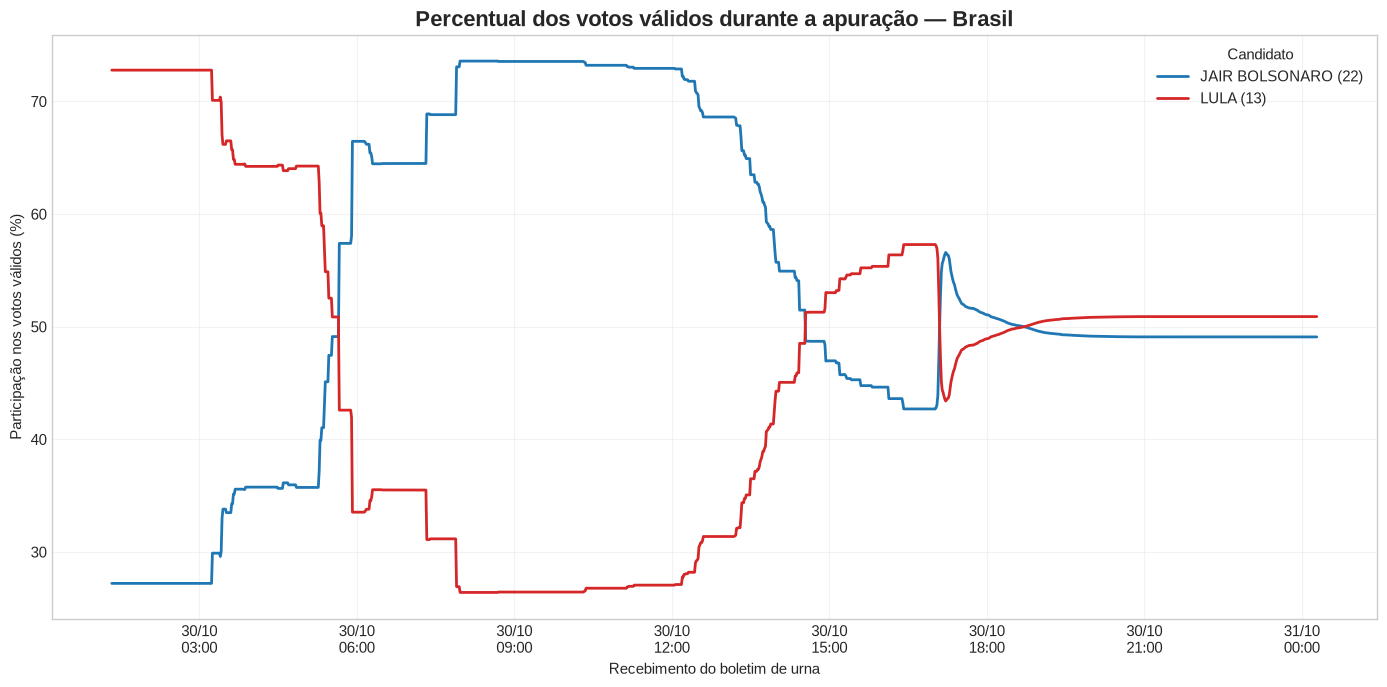

In [7]:
participacao = acumulado.div(acumulado.sum(axis=1), axis=0).mul(100).fillna(0)
fig, ax = plt.subplots()
for candidato in participacao.columns:
    ax.plot(
        participacao.index,
        participacao[candidato],
        label=candidato,
        linewidth=2.0,
        color=cores.get(candidato),
    )

ax.set_title(f"Percentual dos votos válidos durante a apuração — {local}", fontsize=16, weight="bold")
ax.set_xlabel("Recebimento do boletim de urna")
ax.set_ylabel("Participação nos votos válidos (%)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))
ax.legend(title="Candidato", loc="best")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## Ritmo de entrada dos votos

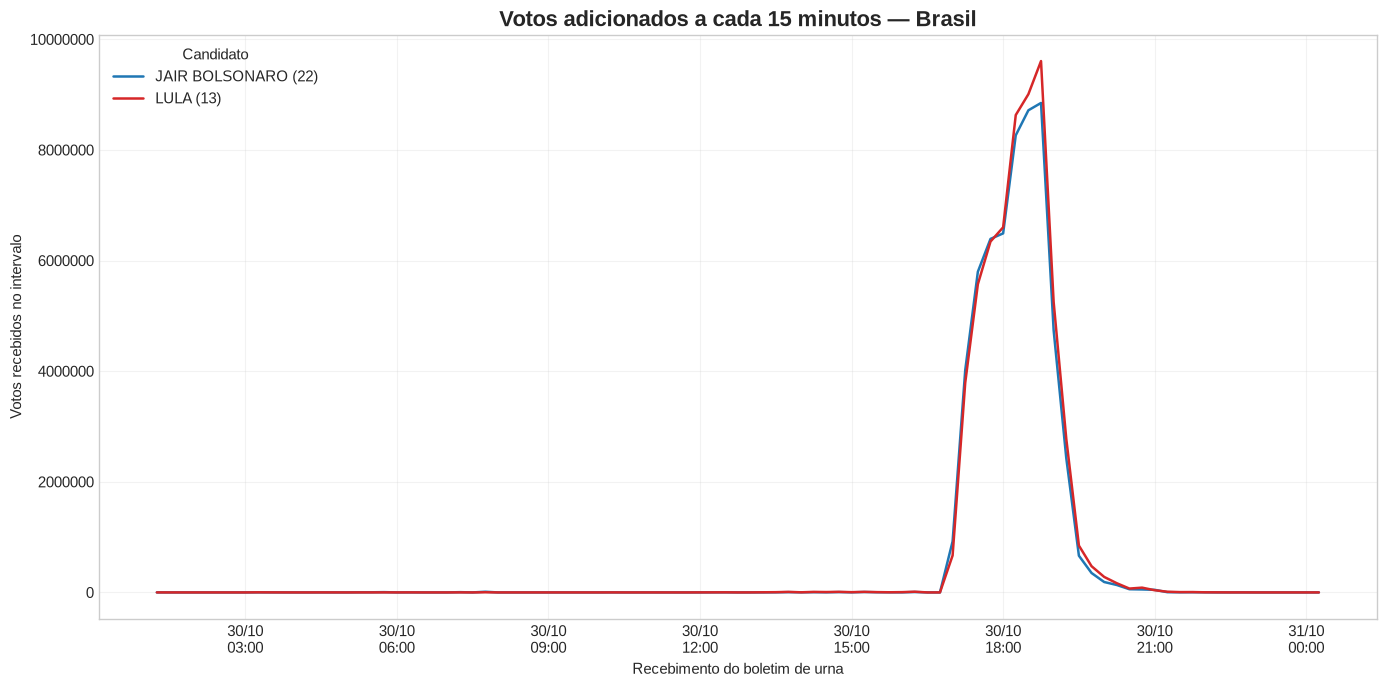

In [8]:
incrementos_15min = incrementos.resample("15min").sum()
fig, ax = plt.subplots()
for candidato in incrementos_15min.columns:
    ax.plot(
        incrementos_15min.index,
        incrementos_15min[candidato],
        label=candidato,
        linewidth=1.8,
        color=cores.get(candidato),
    )

ax.set_title(f"Votos adicionados a cada 15 minutos — {local}", fontsize=16, weight="bold")
ax.set_xlabel("Recebimento do boletim de urna")
ax.set_ylabel("Votos recebidos no intervalo")
ax.ticklabel_format(style="plain", axis="y")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))
ax.legend(title="Candidato", loc="upper left")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## Síntese automática

In [9]:
lider_por_instante = acumulado.idxmax(axis=1)
trocas_lideranca = int(lider_por_instante.ne(lider_por_instante.shift()).sum() - 1)
lider_final = resultado.index[0]
margem_final = int(resultado.iloc[0, 0] - resultado.iloc[1, 0]) if len(resultado) > 1 else 0
pico_por_candidato = incrementos_15min.idxmax()

print(f"Líder ao final da seleção: {lider_final}")
print(f"Margem final entre os dois primeiros: {margem_final:,} votos".replace(",", "."))
print(f"Trocas de liderança observadas na série por minuto: {trocas_lideranca}")
print("\nIntervalo de maior entrada de votos por candidato:")
display(pico_por_candidato.rename("início_do_intervalo_de_15_min").to_frame())
con.close()

Líder ao final da seleção: LULA (13)
Margem final entre os dois primeiros: 2.139.645 votos
Trocas de liderança observadas na série por minuto: 4

Intervalo de maior entrada de votos por candidato:


,início_do_intervalo_de_15_min
candidato,
JAIR BOLSONARO (22),2022-10-30 18:45:00
LULA (13),2022-10-30 18:45:00


## Limitações

- A fonte informa recebimento com precisão de segundos, mas não uma sequência interna
  para boletins com o mesmo horário.
- Existem alertas temporais documentados em `04_bi/auditoria/alertas_temporais.csv`.
- O notebook preserva os horários informados e não tenta corrigi-los por fuso ou por
  comparação com `DT_EMISSAO_BU`.